# TIỀN XỬ LÝ DỮ LIỆU ĐƯỜNG CHUYỀN BÓNG ĐÁ (WYSCOUT EVENT DATA)
### Dự án: Phân cụm đường chuyền bóng đá bằng Grid-based Clustering
**Vai trò:** Thành viên 1 / Data Engineer (Tiền xử lý dữ liệu & Bàn giao)
**Tác giả:** Nhóm Machine Learning Cuối Kỳ
**Dữ liệu:** Bộ sự kiện bóng đá Wyscout công khai (*Pappalardo et al., Scientific Data, 2019*)

---

## Mục tiêu của Notebook này
1. **Đọc dữ liệu thô** trực tiếp từ file nén `events.zip` mà không giải nén tràn ổ đĩa.
2. **Thực thi quy chuẩn tiền xử lý nghiêm ngặt (E1–E13)**:
   - Lọc sự kiện chuyền (`Pass`, `eventId == 8`) trước khi ép kiểu.
   - Loại bỏ các đường chuyền không đủ 2 điểm vị trí (E2) hoặc tọa độ ngoài [0, 100] (E3).
   - **Không xóa** các đường chuyền kết thúc tại `(0, 0)` (E1) mà gắn cờ `end_unknown = True`.
   - Giải mã kết quả chuyền từ tag `1801` (chính xác), `1802` (không chính xác).
   - Giữ nguyên các đường chuyền có điểm đầu trùng điểm cuối (E4) và cầu thủ không xác định (E5).
   - Chuẩn hóa tọa độ về đoạn $[0.0, 1.0]$ nhưng vẫn bảo lưu tọa độ gốc.
   - Sắp xếp chuẩn theo trận đấu, hiệp đấu (`1H, 2H, E1, E2, P`) và thời gian thực `event_sec`.
3. **Kiểm định chất lượng dữ liệu (Data Validation)** theo đúng yêu cầu giảng viên:
   - Số bản ghi sạch $> 500$ dòng.
   - Số cột thông tin gốc $> 10$ cột (bàn giao đủ 21 cột hợp đồng).
   - $100\%$ không chứa giá trị `NaN`/rỗng ở các cột thiết yếu.
4. **Trực quan hóa sân bóng chuẩn** và bàn giao dữ liệu cho Thành viên B (Mô hình) & Thành viên C (Đánh giá).

## 1. Import Thư viện & Thiết lập Môi trường

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import module ETL pipeline đã chuẩn hóa
from pipeline import (
    PipelineConfig,
    setup_logger,
    verify_raw_file,
    load_raw_events,
    check_raw_structure,
    filter_passes,
    extract_coordinates_and_clean,
    normalize_and_add_derived_features,
    sort_and_finalize,
    validate_dataset,
    generate_pitch_visualizations,
    scan_and_propose_matches,
    export_artifacts,
    run_pipeline,
)

print(f"Python Version: {sys.version}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")

Python Version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
Pandas Version: 3.1.1
NumPy Version:  2.5.4


## 2. Xác minh Tính toàn vẹn File Dữ liệu Thô (Step S1)
Kiểm tra kích thước byte và mã băm MD5 của `events.zip` để đối chiếu với thông số chuẩn đã kiểm chứng.

In [2]:
ZIP_PATH = "D:/events.zip"
logger = setup_logger()

verify_result = verify_raw_file(ZIP_PATH, logger)
pd.DataFrame([verify_result])

[2026-11-15 16:48:26] [INFO] Step S1: Verifying raw ZIP file: D:/events.zip


[2026-11-15 16:48:26] [INFO]   Size: 77,323,413 bytes (Expected: 77,323,413 bytes) -> MATCH


[2026-11-15 16:48:26] [INFO]   MD5 : 7c20e8647e7eda58d7838a0c7b1ec6ab (Expected: 7c20e8647e7eda58d7838a0c7b1ec6ab) -> MATCH


,zip_path,actual_size,expected_size,size_matched,actual_md5,expected_md5,md5_matched
0,D:\events.zip,77323413,77323413,True,7c20e8647e7eda58d7838a0c7b1ec6ab,7c20e8647e7eda58d7838a0c7b1ec6ab,True


## 3. Quét & Đề xuất Trận đấu Phù hợp (Section 8)
Áp dụng 4 tiêu chí khắt khe để chọn trận đấu mẫu:
1. Không có sự kiện bị loại do lỗi vị trí (E2, E3).
2. Tổng số đường chuyền $\ge 800$.
3. Tỷ lệ chuyền giữa hai đội $\ge 0.85$ (tránh trận đấu một chiều áp đảo).
4. Đủ 2 đội thi đấu cân bằng.

In [3]:
candidates = scan_and_propose_matches(
    zip_path=ZIP_PATH,
    json_filenames=["events_European_Championship.json"],
    logger=logger,
    min_passes=800,
    min_ratio=0.85,
)

cand_df = pd.DataFrame([
    {
        "file": c.file_name,
        "match_id": c.match_id,
        "total_passes": c.total_passes,
        "team_1_passes": c.team_counts[0],
        "team_2_passes": c.team_counts[1],
        "balance_ratio": round(c.balance_ratio, 4),
    }
    for c in candidates
])
cand_df

[2026-11-15 16:48:26] [INFO] Scanning for candidate matches according to Section 8 criteria...


[2026-11-15 16:48:26] [INFO]   [Candidate] events_European_Championship.json | Match 1694397 | Passes: 813 | Teams: 426/387 (Ratio: 0.9085)


[2026-11-15 16:48:26] [INFO]   [Candidate] events_European_Championship.json | Match 1694401 | Passes: 923 | Teams: 448/475 (Ratio: 0.9432)


[2026-11-15 16:48:26] [INFO]   [Candidate] events_European_Championship.json | Match 1694416 | Passes: 859 | Teams: 441/418 (Ratio: 0.9478)


[2026-11-15 16:48:26] [INFO]   [Candidate] events_European_Championship.json | Match 1694431 | Passes: 860 | Teams: 398/462 (Ratio: 0.8615)


[2026-11-15 16:48:26] [INFO]   [Candidate] events_European_Championship.json | Match 1694434 | Passes: 1194 | Teams: 630/564 (Ratio: 0.8952)


,file,match_id,total_passes,team_1_passes,team_2_passes,balance_ratio
0,events_European_Championship.json,1694397,813,426,387,0.9085
1,events_European_Championship.json,1694401,923,448,475,0.9432
2,events_European_Championship.json,1694416,859,441,418,0.9478
3,events_European_Championship.json,1694431,860,398,462,0.8615
4,events_European_Championship.json,1694434,1194,630,564,0.8952


## 4. Thực thi Toàn bộ ETL Pipeline
Chúng ta chọn 2 trận Euro tiêu biểu nhất: `1694401` và `1694416` (đều có tỷ lệ cân bằng $> 0.94$).

In [4]:
config = PipelineConfig(
    zip_path=ZIP_PATH,
    json_files=["events_European_Championship.json"],
    target_match_ids=[1694401, 1694416],
    output_dir="D:/ML_ck",
)

df_clean, val_report = run_pipeline(config, logger)

[2026-11-15 16:48:26] [INFO] ======================================================================


[2026-11-15 16:48:26] [INFO] STARTING SOCCER PASS PREPROCESSING ETL PIPELINE


[2026-11-15 16:48:26] [INFO] Config: Zip Path = D:/events.zip


[2026-11-15 16:48:26] [INFO] Config: JSON Files = ['events_European_Championship.json']


[2026-11-15 16:48:26] [INFO] Config: Target Matches = [1694401, 1694416]


[2026-11-15 16:48:26] [INFO] ======================================================================


... (44 outputs left out)

[2026-11-15 16:48:29] [INFO]   Quality audit report saved: D:/ML_ck\data_quality_report.md


[2026-11-15 16:48:29] [INFO] ======================================================================


[2026-11-15 16:48:29] [INFO] ETL PIPELINE COMPLETED SUCCESSFULLY!


[2026-11-15 16:48:29] [INFO] ======================================================================


## 5. Kiểm tra Schema Hợp đồng Dữ liệu (Data Contract Schema - 21 Cột)
Hiển thị cấu trúc dữ liệu đã được làm sạch và bàn giao.

In [5]:
print(f"Kích thước DataFrame: {df_clean.shape[0]} dòng, {df_clean.shape[1]} cột\n")
schema_info = pd.DataFrame({
    "Kiểu dữ liệu (dtype)": df_clean.dtypes,
    "Số lượng Null": df_clean.isnull().sum(),
    "Mẫu giá trị dòng đầu": df_clean.iloc[0]
})
schema_info

Kích thước DataFrame: 1782 dòng, 21 cột



,Kiểu dữ liệu (dtype),Số lượng Null,Mẫu giá trị dòng đầu
event_id,int64,0,88802646
match_id,int64,0,1694401
team_id,int64,0,14358
player_id,int64,0,101669
match_period,str,0,1H
event_sec,float64,0,1.948957
sub_event_id,int64,0,85
sub_event_name,str,0,Simple pass
x_start,int64,0,50
y_start,int64,0,49


## 6. Kiểm định Ngưỡng Giảng viên (Assertion Verification)
Bảng tổng hợp đối chiếu kết quả thực tế với mọi ràng buộc của đề tài.

In [6]:
assertions_summary = pd.DataFrame([
    {"Tiêu chí": "Số dòng dữ liệu sạch", "Ràng buộc": "> 500 dòng", "Thực tế": f"{val_report.row_count:,} dòng", "Kết quả": "PASS" if val_report.row_count_valid else "FAIL"},
    {"Tiêu chí": "Số cột thông tin gốc", "Ràng buộc": "> 10 cột", "Thực tế": f"{val_report.raw_col_count} cột", "Kết quả": "PASS" if val_report.raw_col_count_valid else "FAIL"},
    {"Tiêu chí": "Tổng số cột bàn giao", "Ràng buộc": "Đúng 21 cột", "Thực tế": f"{val_report.total_col_count} cột", "Kết quả": "PASS" if val_report.total_col_count_valid else "FAIL"},
    {"Tiêu chí": "Không chứa giá trị Null", "Ràng buộc": "0 null", "Thực tế": f"{sum(val_report.null_counts.values())} null", "Kết quả": "PASS" if val_report.no_nulls_valid else "FAIL"},
    {"Tiêu chí": "Tính duy nhất của event_id", "Ràng buộc": "Unique", "Thực tế": "Không trùng lặp", "Kết quả": "PASS" if val_report.is_event_id_unique else "FAIL"},
    {"Tiêu chí": "Tọa độ chuẩn hóa trong [0, 1]", "Ràng buộc": "[0.0, 1.0]", "Thực tế": f"[{df_clean['x_start_n'].min():.2f}, {df_clean['x_start_n'].max():.2f}]", "Kết quả": "PASS" if val_report.coord_norm_valid else "FAIL"},
    {"Tiêu chí": "Số đội mỗi trận đấu", "Ràng buộc": "Đúng 2 đội/trận", "Thực tế": str(val_report.teams_per_match), "Kết quả": "PASS" if val_report.teams_per_match_valid else "FAIL"},
])
assertions_summary

,Tiêu chí,Ràng buộc,Thực tế,Kết quả
0,Số dòng dữ liệu sạch,> 500 dòng,"1,782 dòng",PASS
1,Số cột thông tin gốc,> 10 cột,13 cột,PASS
2,Tổng số cột bàn giao,Đúng 21 cột,21 cột,PASS
3,Không chứa giá trị Null,0 null,0 null,PASS
4,Tính duy nhất của event_id,Unique,Không trùng lặp,PASS
5,"Tọa độ chuẩn hóa trong [0, 1]","[0.0, 1.0]","[0.02, 1.00]",PASS
6,Số đội mỗi trận đấu,Đúng 2 đội/trận,"{1694401: 2, 1694416: 2}",PASS


## 7. Trực quan hóa Dữ liệu trên Sơ đồ Sân Bóng Chuẩn
Xem xét trực quan phân bố vị trí chuyền bóng và các vector đường chuyền.

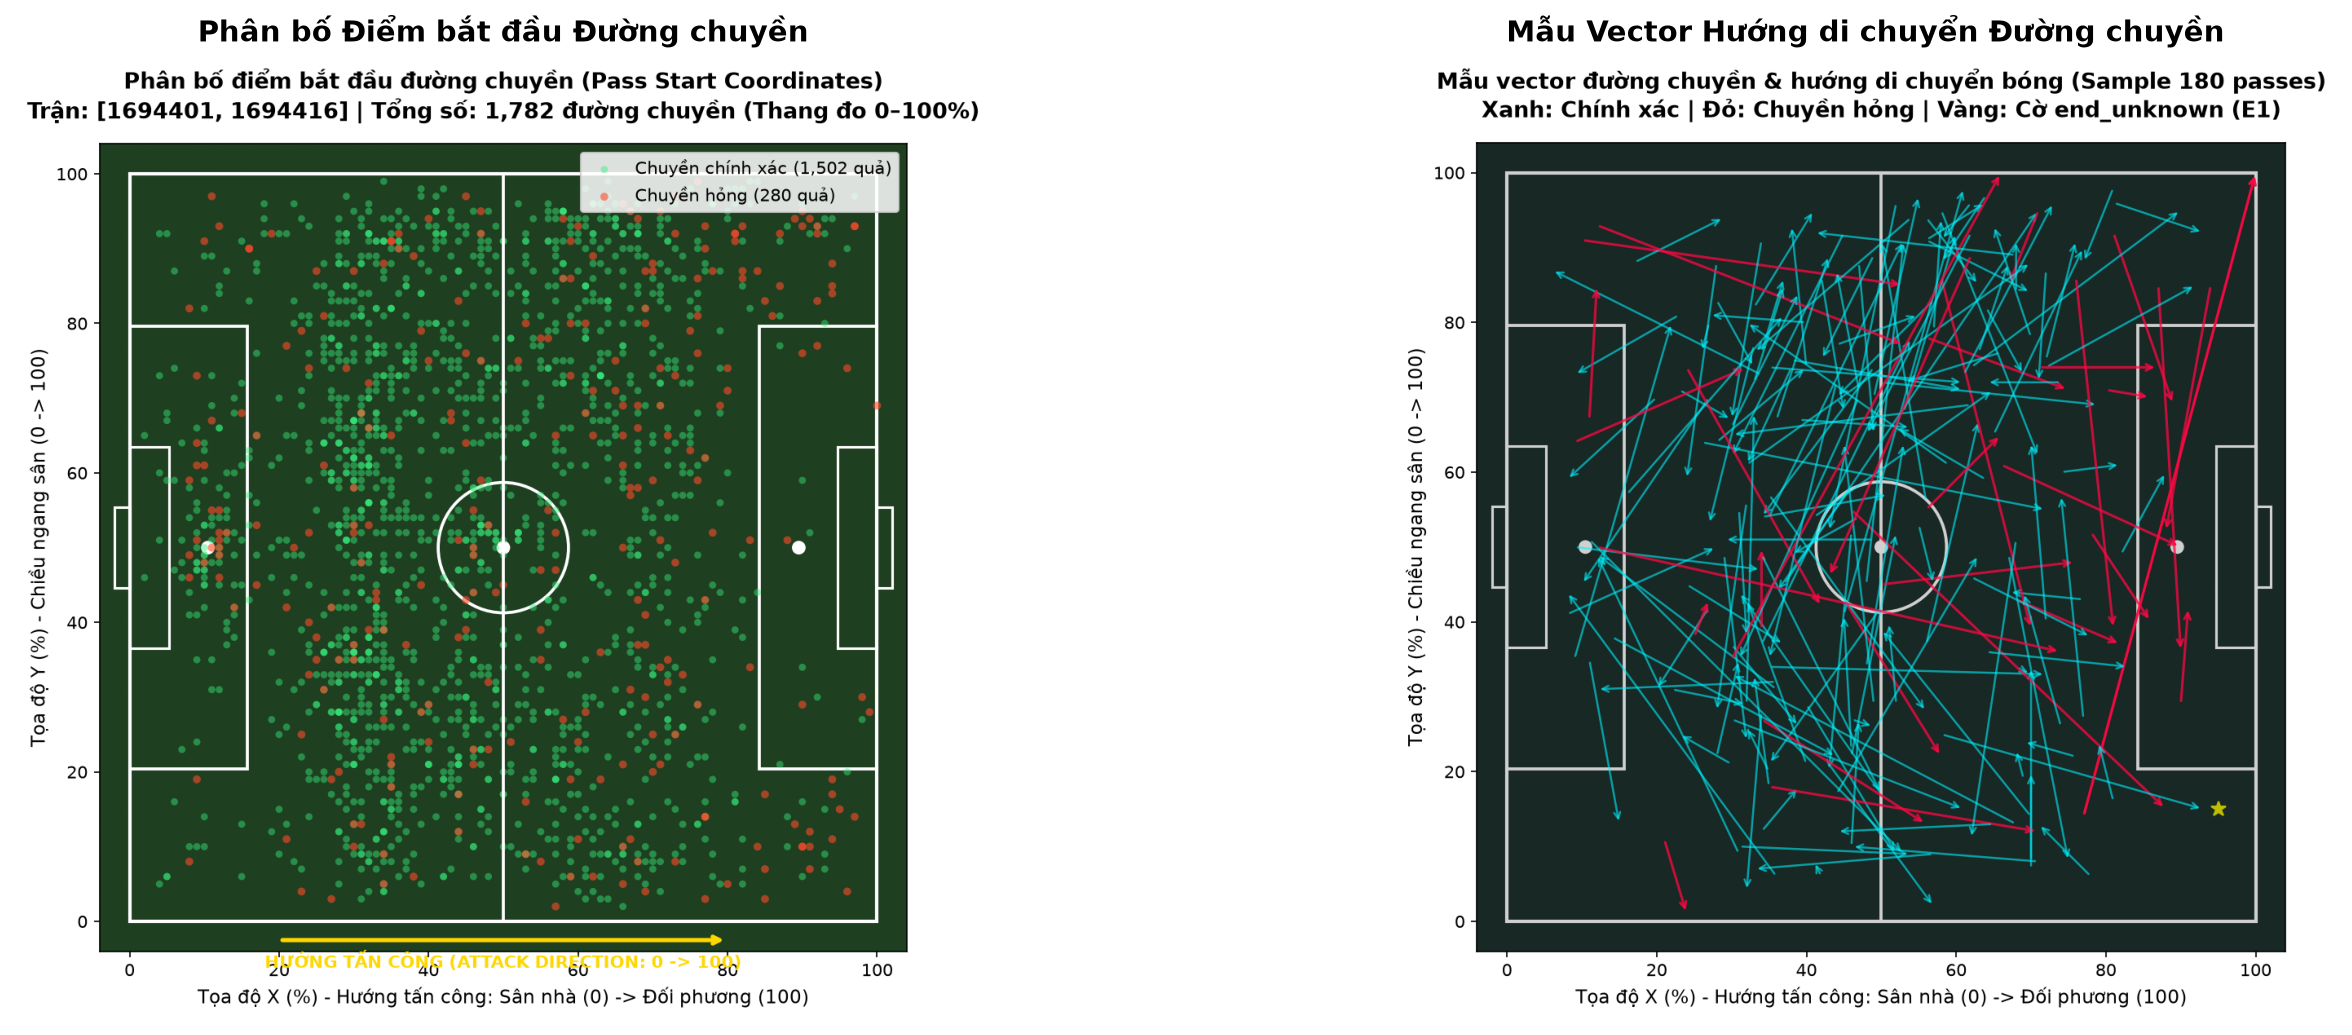

In [7]:
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(20, 7), dpi=150)

img_dist = Image.open("D:/ML_ck/pitch_pass_distribution.png")
axes[0].imshow(img_dist)
axes[0].axis("off")
axes[0].set_title("Phân bố Điểm bắt đầu Đường chuyền", fontsize=14, fontweight="bold")

img_dir = Image.open("D:/ML_ck/pitch_pass_directions.png")
axes[1].imshow(img_dir)
axes[1].axis("off")
axes[1].set_title("Mẫu Vector Hướng di chuyển Đường chuyền", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

## 8. Hướng dẫn Bàn giao cho Thành viên B & C

### 📌 Hướng dẫn cho Thành viên B (Cài đặt Thuật toán Grid-based):
1. **Phân cụm 2D:**
   - Input: 2 cột `x_start_n`, `y_start_n`.
   - Kích thước tập dữ liệu: Toàn bộ **1,782 dòng**.
   - **Lưu ý quan trọng về giá trị biên 1.0 (E8):** Khi chia các ô lưới theo chiều $X$ và $Y$ (ví dụ lưới $10 \times 10$, kích thước mỗi ô là $0.1$):
     - Tọa độ chạm biên phải hoặc biên trên có giá trị chính xác `1.0`.
     - Nếu dùng phép tính `int(coord / 0.1)`, giá trị `1.0 / 0.1 = 10` sẽ làm lỗi tràn mảng (IndexError vì chỉ số ô hợp lệ là $0 \dots 9$).
     - **Bắt buộc** B phải gộp giá trị `1.0` vào ô cuối cùng bằng cách:  
       ```python
       bin_x = min(int(x / bin_size), n_bins_x - 1)
       bin_y = min(int(y / bin_size), n_bins_y - 1)
       ```
2. **Phân cụm 4D (Mở rộng):**
   - Input: 4 cột `x_start_n`, `y_start_n`, `x_end_n`, `y_end_n`.
   - **Bắt buộc lọc bỏ các dòng có cờ `end_unknown == True` (E1)**:  
     ```python
     df_4d = df_clean[~df_clean['end_unknown']]
     ```
   - Dữ liệu 4D sạch còn lại: **1,773 dòng** (vẫn hoàn toàn vượt ngưỡng $>500$ dòng của giảng viên).

### 📌 Hướng dẫn cho Thành viên C (Đánh giá & Slide Thuyết trình):
1. Lấy trực tiếp các con số ở **Mục 2 và Mục 6** để đưa vào Slide 1–3 (Phần Giới thiệu đề tài & Tiền xử lý dữ liệu).
2. File ảnh `pitch_pass_distribution.png` và `pitch_pass_directions.png` có độ phân giải cao, sẵn sàng chèn vào bài thuyết trình.